# Recurrent SLDS: the NASCAR example

In a *recurrent* switching linear dynamical system (rSLDS; Linderman et al., 2017) the discrete state transitions depend
on the continuous state,

$$p(z_{t+1} = j \mid z_t = i, x_t) = \mathrm{softmax}_j\big(\mathrm{logits}[i, j] + W_x[j] \cdot x_t\big),$$

so the discrete states partition the continuous state space into regions with their own linear dynamics. With
`recurrent_only=True` the $K \times K$ logits collapse to a single bias row and the partition alone drives the switching.

This notebook reproduces the "NASCAR" example of the paper (and of `ssm`'s rSLDS notebook): two states rotate the
continuous state around $(+2, 0)$ and $(-2, 0)$, two move it straight along the top and bottom of the track, and the
recurrent weights carve the plane into right / left / top / bottom. We simulate the system, fit an rSLDS from the
PCA + ARHMM initialization with Laplace variational EM, and compare the learned partition with the truth.

## Setup

In [1]:
%%capture
try:
    import dynamax
except ModuleNotFoundError:
    print('installing dynamax')
    %pip install -q dynamax[notebooks]
    import dynamax

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
from matplotlib import pyplot as plt

from dynamax.slds import RecurrentGaussianSLDS
from dynamax.utils.utils import find_permutation

## The NASCAR model

`make_nascar_params` sets the parameters by hand: diagonal dynamics noise $Q_k = 10^{-4} I$, a shared emission
model with a random orthonormal $H$ (10 observed dimensions) and isotropic noise $R = 10^{-2} I$, and
recurrent-only transitions whose weights $W_x$ and biases define the four regions.

In [3]:
num_states, state_dim, emission_dim, num_timesteps = 4, 2, 10, 2000


def make_nascar_params(model, key=jr.PRNGKey(0)):
    params, props = model.initialize(key)
    rotation = lambda angle: jnp.array([[jnp.cos(angle), -jnp.sin(angle)], [jnp.sin(angle), jnp.cos(angle)]])
    As = [rotation(-jnp.pi / 24), rotation(-jnp.pi / 48), jnp.eye(state_dim), jnp.eye(state_dim)]
    centers = [jnp.array([2.0, 0.0]), jnp.array([-2.0, 0.0])]
    bs = [-(A - jnp.eye(state_dim)) @ c for A, c in zip(As[:2], centers)] + [jnp.array([0.1, 0.0]), jnp.array([-0.25, 0.0])]
    recurrent_weights = jnp.array([[100.0, 0.0], [-100.0, 0.0], [0.0, 10.0], [0.0, -10.0]])
    logits = jnp.array([[-200.0, -200.0, 0.0, 0.0]])
    H = jnp.linalg.qr(jr.normal(jr.fold_in(key, 7), (emission_dim, state_dim)))[0]
    params = params._replace(
        initial=params.initial._replace(probs=jnp.array([0.0, 0.0, 1.0, 0.0])),
        transitions=params.transitions._replace(logits=logits, recurrent_weights=recurrent_weights),
        dynamics=params.dynamics._replace(initial_mean=jnp.array([0.0, 1.0]), initial_cov=1e-4 * jnp.eye(state_dim),
                                          weights=jnp.stack(As), biases=jnp.stack(bs), covs=1e-4 * jnp.ones((num_states, state_dim))),
        emissions=params.emissions._replace(weights=H[None], biases=jnp.zeros((1, emission_dim)), covs=1e-2 * jnp.ones((1, emission_dim))))
    return params, props


true_model = RecurrentGaussianSLDS(num_states, state_dim, emission_dim, recurrent_only=True, dynamics_cov_type="diag")
true_params, _ = make_nascar_params(true_model)
true_states, true_latents, emissions = true_model.sample(true_params, jr.PRNGKey(2), num_timesteps)

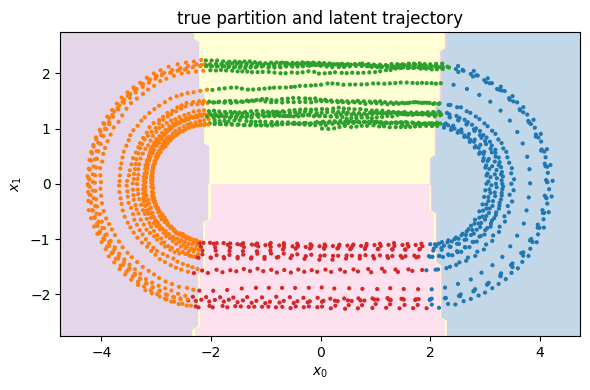

In [4]:
def plot_partition(ax, recurrent_weights, logits, x, states, title):
    # color the plane by argmax_j (W_j . x + r_j) and overlay the trajectory colored by state
    grid_x, grid_y = jnp.meshgrid(jnp.linspace(x[:, 0].min() - 0.5, x[:, 0].max() + 0.5, 100),
                                  jnp.linspace(x[:, 1].min() - 0.5, x[:, 1].max() + 0.5, 100))
    grid = jnp.stack([grid_x.ravel(), grid_y.ravel()], 1)
    region = jnp.argmax(grid @ recurrent_weights.T + logits[0], axis=1).reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, region, levels=jnp.arange(num_states + 1) - 0.5, cmap="Pastel1", alpha=0.8)
    ax.scatter(x[:, 0], x[:, 1], c=states, cmap="tab10", vmin=0, vmax=9, s=4)
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
plot_partition(ax, true_params.transitions.recurrent_weights, true_params.transitions.logits, true_latents, true_states, "true partition and latent trajectory")
plt.tight_layout()

## Fitting

The variational posterior uses Monte Carlo samples of $x$ (one per sweep by default, as `ssm`) for the transition
terms, and $q(x)$ is a Laplace approximation found by Newton's method. The recurrent transition parameters have no
closed-form M-step; they are updated by L-BFGS on the expected log joint. The reported objective is therefore noisy
and not guaranteed to be monotone. On this stiff problem (dynamics noise 1e-4, partition weights of 100) the variational
fit is also sensitive to the data and to the initialization: across seeds the state accuracy ranges from about 0.65 to 0.9,
so in practice one compares several restarts by their final objective.

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:10&lt;00:00]</div>

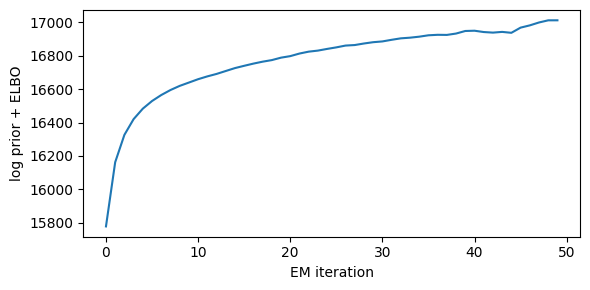

In [5]:
model = RecurrentGaussianSLDS(num_states, state_dim, emission_dim, recurrent_only=True, dynamics_cov_type="diag")
params, props = model.initialize(jr.PRNGKey(2), method="pca_arhmm", emissions=emissions)
fitted_params, log_probs, posterior = model.fit_em(params, props, emissions, num_iters=50, return_posterior=True)

plt.figure(figsize=(6, 3))
plt.plot(log_probs)
plt.xlabel("EM iteration"); plt.ylabel("log prior + ELBO")
plt.tight_layout()

## Learned partition

The latent space is only identified up to an affine map $x \to G x + g$, so we align the posterior mean with the true
latents before comparing. The recurrent weights transform accordingly ($W \to W G^{-1}$), and the state labels are
matched with `find_permutation`.

discrete state accuracy: 0.908
RMSE of the aligned posterior mean: 0.035


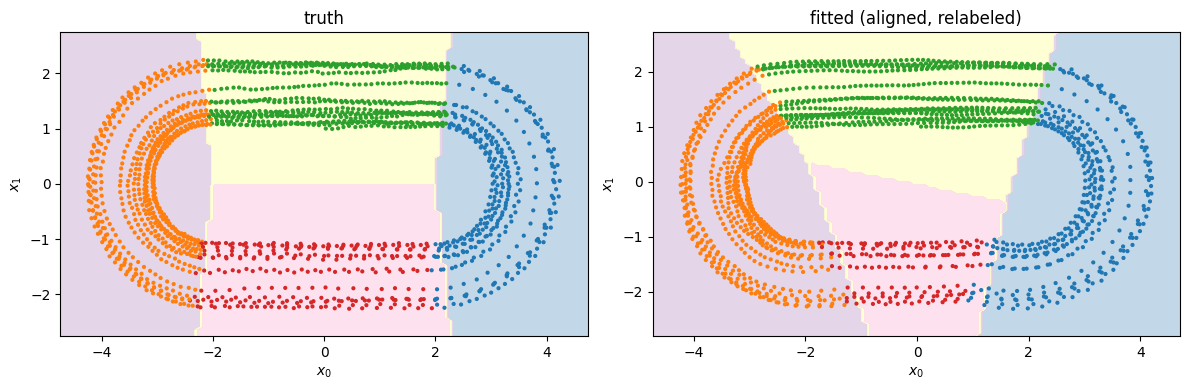

In [6]:
posterior = jax.tree_util.tree_map(lambda a: a[0], posterior)
inferred_states = model.most_likely_states(fitted_params, emissions, posterior)
permutation = find_permutation(inferred_states, true_states)
print(f"discrete state accuracy: {jnp.mean(permutation[inferred_states] == true_states):.3f}")

posterior_means = posterior.continuous.smoothed_means
design = jnp.concatenate([posterior_means, jnp.ones((num_timesteps, 1))], axis=1)
coef = jnp.linalg.lstsq(design, true_latents)[0]
G, g = coef[:-1].T, coef[-1]
aligned_means = design @ coef
print(f"RMSE of the aligned posterior mean: {jnp.sqrt(jnp.mean((aligned_means - true_latents) ** 2)):.3f}")

# the fitted partition in the aligned coordinates: W x̂ + r = (W G^{-1}) (x - g) + r
W_aligned = fitted_params.transitions.recurrent_weights @ jnp.linalg.inv(G)
r_aligned = fitted_params.transitions.logits - (W_aligned @ g)[None]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_partition(axes[0], true_params.transitions.recurrent_weights, true_params.transitions.logits, true_latents, true_states, "truth")
relabel = jnp.argsort(permutation)                      # fitted state j -> true state permutation[j]
plot_partition(axes[1], W_aligned[relabel], r_aligned[:, relabel], aligned_means, permutation[inferred_states], "fitted (aligned, relabeled)")
plt.tight_layout()

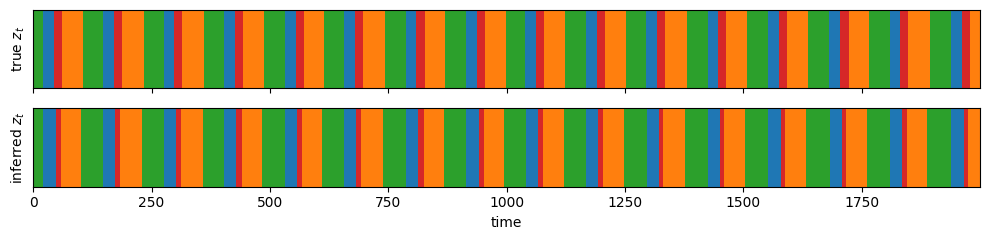

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 2.5), sharex=True)
for ax, states, title in zip(axes, [true_states, permutation[inferred_states]], ["true $z_t$", "inferred $z_t$"]):
    ax.imshow(states[None], aspect="auto", cmap="tab10", vmin=0, vmax=9, interpolation="none")
    ax.set_yticks([]); ax.set_ylabel(title)
axes[1].set_xlabel("time")
plt.tight_layout()